<a href="https://colab.research.google.com/github/arsingla786/ImageProcessing/blob/main/assignment_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

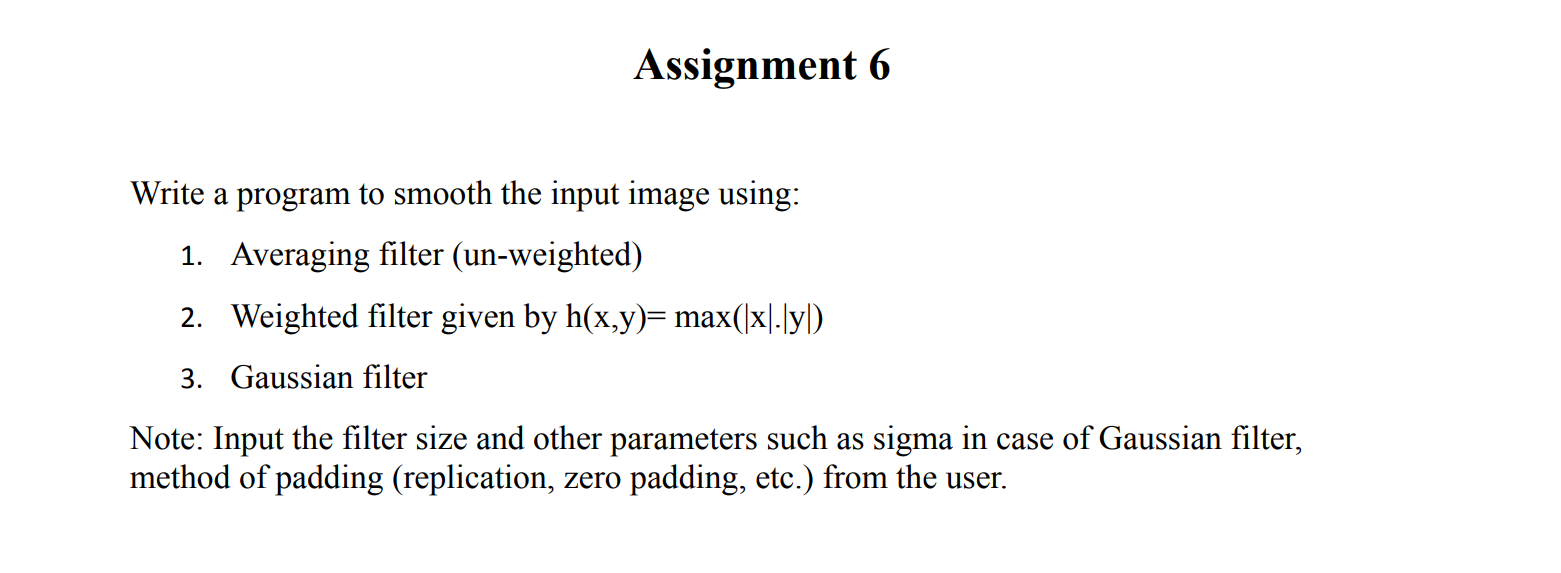

In [1]:
import pandas as pd
import numpy as np
import cv2

In [6]:
img_path = '/content/Screenshot 2026-10-27 100414.png'
img = cv2.imread(img_path)

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
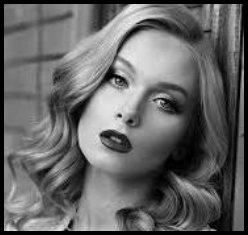

In [7]:
img

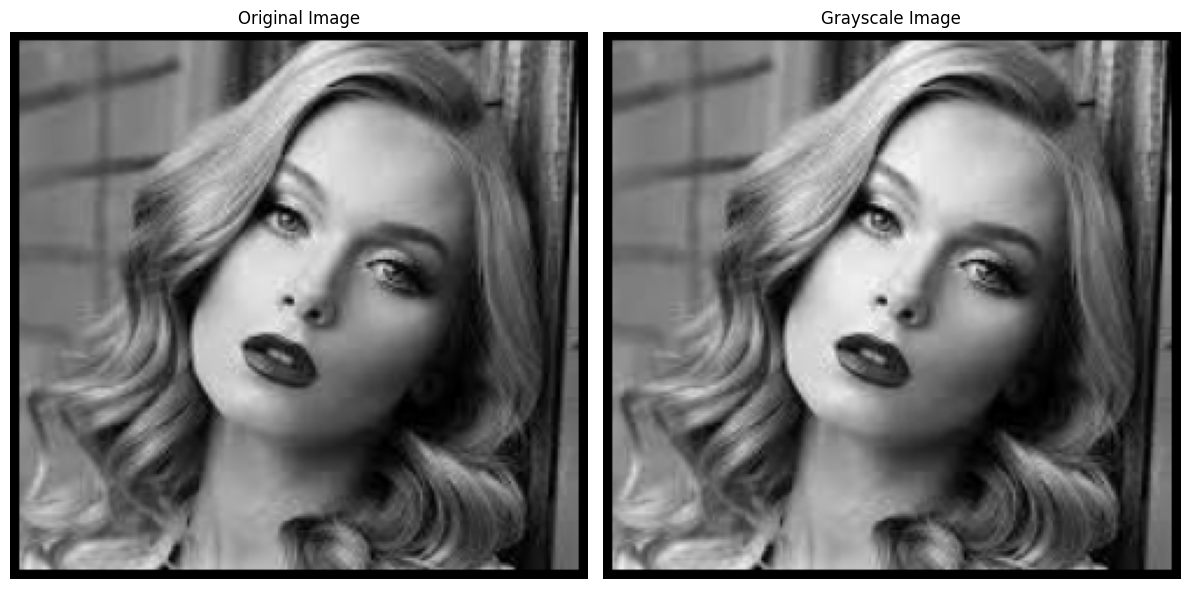

In [8]:
import matplotlib.pyplot as plt

# Convert the image from BGR to grayscale
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Display the original and grayscale images side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(gray_img, cmap='gray')
axes[1].set_title('Grayscale Image')
axes[1].axis('off')

plt.tight_layout()
plt.show()

New shape: (255, 255)


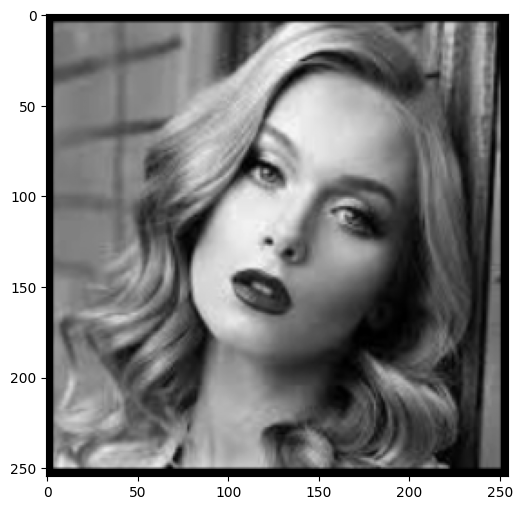

In [9]:
# Resize the grayscale image to 255x255
gray_img = cv2.resize(gray_img, (255, 255))
print("New shape:",gray_img.shape)

# Display the resized grayscale image
plt.figure(figsize=(6, 6))
plt.imshow(gray_img, cmap='gray')


### 1. Smoothing using an Averaging Filter (Un-weighted)

An un-weighted averaging filter smooths the image by replacing each pixel value with the mean (average) of its neighborhood pixels. We will apply this using OpenCV's `cv2.blur` function.

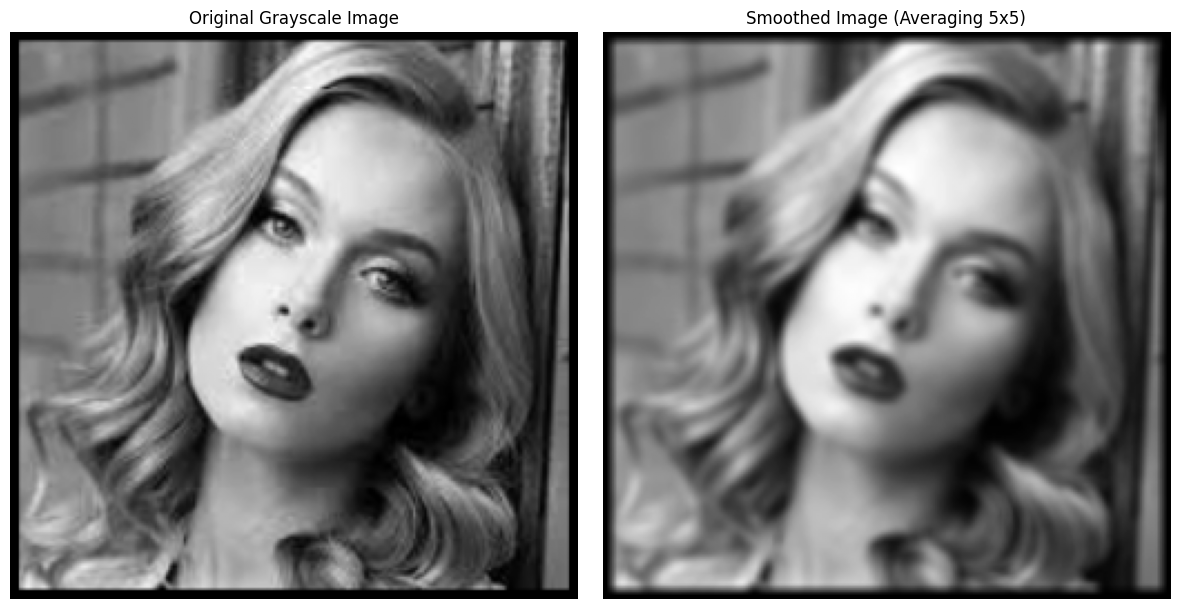

In [10]:
# Define the kernel size for the averaging filter
kernel_size = (5, 5)

# Apply the un-weighted averaging filter (box filter)
smoothed_img = cv2.blur(gray_img, kernel_size)

# Display the original grayscale image and the smoothed image side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(gray_img, cmap='gray')
axes[0].set_title('Original Grayscale Image')
axes[0].axis('off')

axes[1].imshow(smoothed_img, cmap='gray')
axes[1].set_title(f'Smoothed Image (Averaging {kernel_size[0]}x{kernel_size[1]})')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### 2. Smoothing using a Weighted Filter: $h(x,y) = \max(|x|, |y|)$

We will construct a spatial filter kernel of size $(5 \times 5)$ centered at $(0,0)$, where the coordinate offsets $x$ and $y$ range from $-2$ to $+2$.

For each position $(x, y)$, the weight is $h(x,y) = \max(|x|, |y|)$. After constructing the grid, we normalize the kernel by dividing all elements by the sum of its values so that the filter preserves the overall brightness of the image.

Generated Kernel:
 [[2. 2. 2. 2. 2.]
 [2. 1. 1. 1. 2.]
 [2. 1. 0. 1. 2.]
 [2. 1. 1. 1. 2.]
 [2. 2. 2. 2. 2.]]

Normalized Kernel:
 [[0.05  0.05  0.05  0.05  0.05 ]
 [0.05  0.025 0.025 0.025 0.05 ]
 [0.05  0.025 0.    0.025 0.05 ]
 [0.05  0.025 0.025 0.025 0.05 ]
 [0.05  0.05  0.05  0.05  0.05 ]]


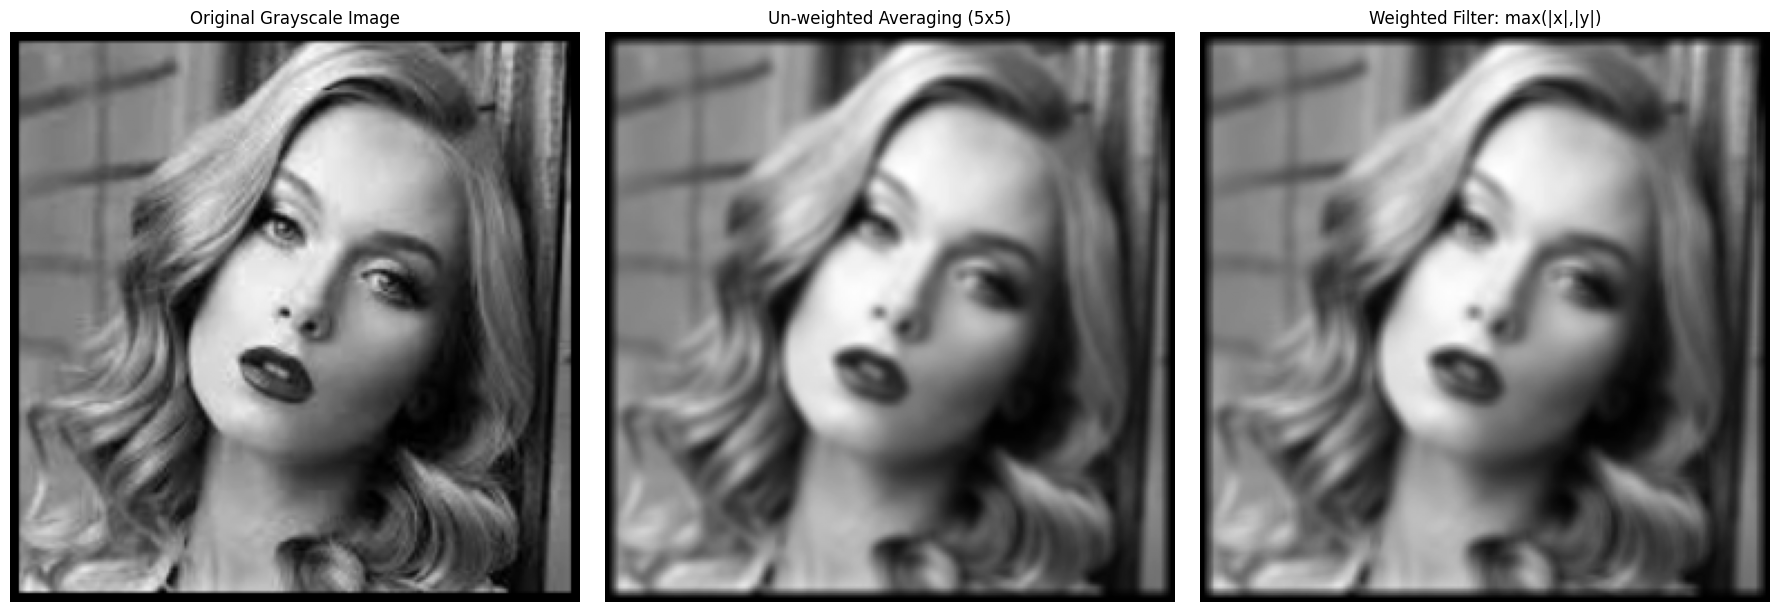

In [11]:
# Define kernel size (must be odd)
k_size = 5
radius = k_size // 2

# Create a coordinate grid centered at (0,0)
y, x = np.ogrid[-radius:radius+1, -radius:radius+1]

# Calculate the custom weights h(x,y) = max(|x|, |y|)
custom_kernel = np.maximum(np.abs(x), np.abs(y)).astype(np.float32)

# Normalize the kernel to ensure the sum of weights is 1
# (Avoid division by zero if the entire kernel sum is 0, though not possible here)
if custom_kernel.sum() > 0:
    normalized_kernel = custom_kernel / custom_kernel.sum()
else:
    normalized_kernel = custom_kernel

print("Generated Kernel:\n", custom_kernel)
print("\nNormalized Kernel:\n", normalized_kernel)

# Filter the image using the custom kernel
weighted_smoothed_img = cv2.filter2D(gray_img, -1, normalized_kernel)

# Display the original, un-weighted smoothed, and weighted smoothed images
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(gray_img, cmap='gray')
axes[0].set_title('Original Grayscale Image')
axes[0].axis('off')

axes[1].imshow(smoothed_img, cmap='gray')
axes[1].set_title('Un-weighted Averaging (5x5)')
axes[1].axis('off')

axes[2].imshow(weighted_smoothed_img, cmap='gray')
axes[2].set_title('Weighted Filter: max(|x|,|y|)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

### 3. Smoothing using a Gaussian Filter

A Gaussian filter smooths the image by convolving it with a Gaussian kernel. This places more weight on the center pixel and less weight on pixels further away, preserving edges better than a simple box filter.

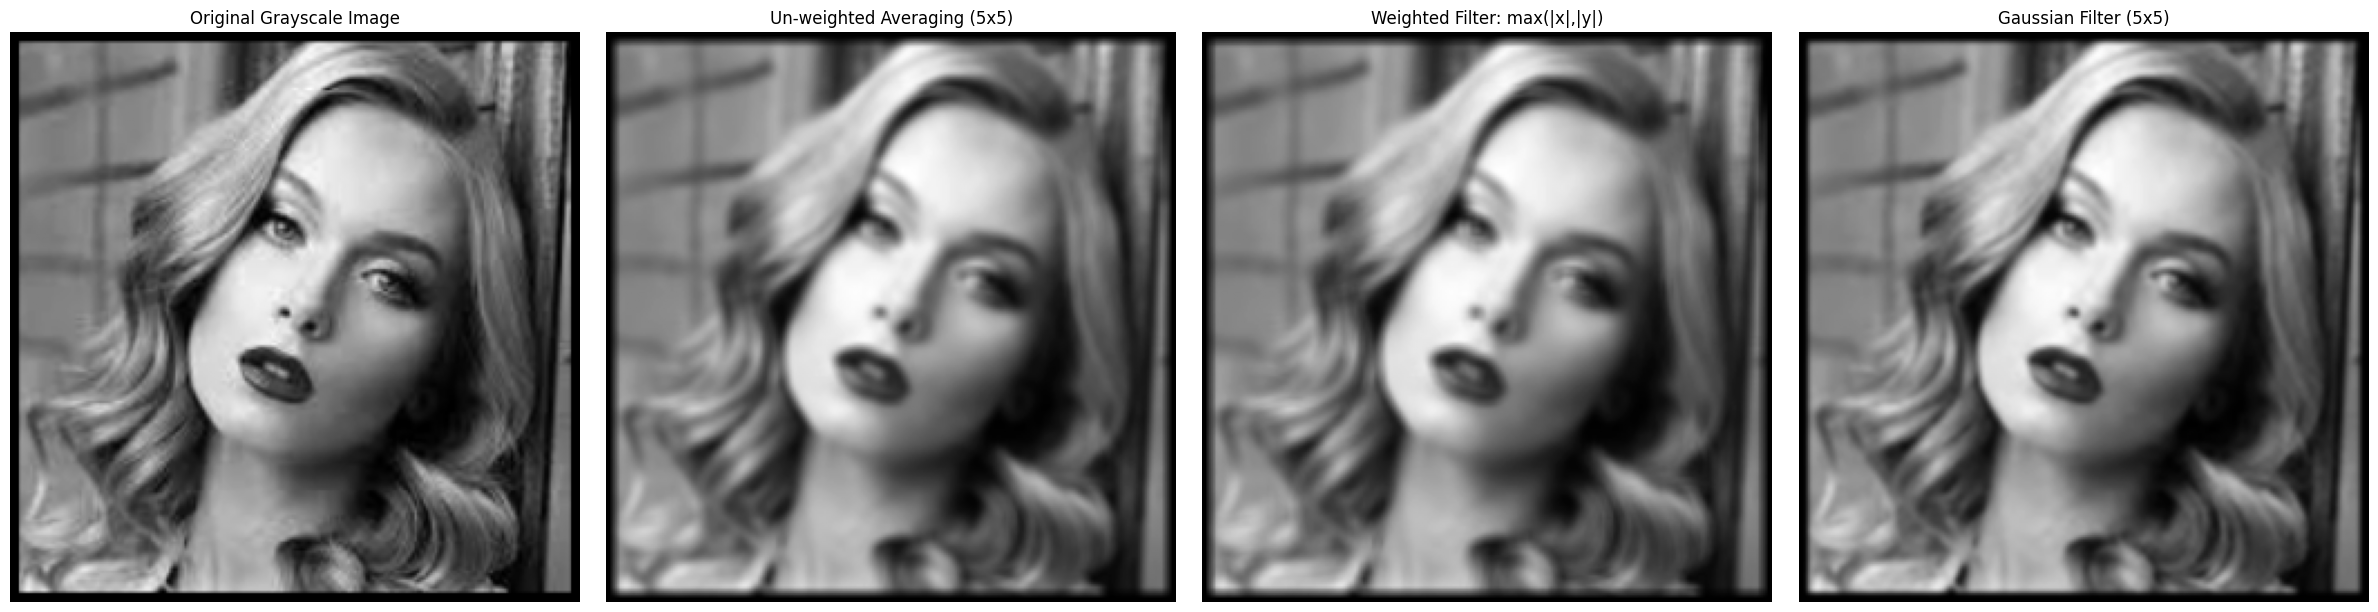

In [12]:
# Apply Gaussian blur with a 5x5 kernel
gaussian_smoothed_img = cv2.GaussianBlur(gray_img, (5, 5), sigmaX=0)

# Display the results side-by-side
fig, axes = plt.subplots(1, 4, figsize=(24, 6))

axes[0].imshow(gray_img, cmap='gray')
axes[0].set_title('Original Grayscale Image')
axes[0].axis('off')

axes[1].imshow(smoothed_img, cmap='gray')
axes[1].set_title('Un-weighted Averaging (5x5)')
axes[1].axis('off')

axes[2].imshow(weighted_smoothed_img, cmap='gray')
axes[2].set_title('Weighted Filter: max(|x|,|y|)')
axes[2].axis('off')

axes[3].imshow(gaussian_smoothed_img, cmap='gray')
axes[3].set_title('Gaussian Filter (5x5)')
axes[3].axis('off')

plt.tight_layout()
plt.show()